In [ ]:
# CAPSTONE 51 - Image Classification Mini-Project
# Step 1: Verify the Python environment

print("CAPSTONE 51")
print("Image Classification Mini-Project with Hugging Face")
print("Project environment is ready!")

CAPSTONE 51
Image Classification Mini-Project with Hugging Face
Project environment is ready!


In [ ]:
# CAPSTONE 51 - Step 2: Install AI libraries

%pip install -q transformers torch pillow


In [ ]:
# CAPSTONE 51 - Step 3: Verify the libraries

import transformers
import torch
import PIL

print("Transformers version:", transformers.__version__)
print("PyTorch version:", torch.__version__)
print("Pillow version:", PIL.__version__)

print("\nAll required libraries imported successfully!")

Transformers version: 5.20.1
PyTorch version: 2.11.0+cpu
Pillow version: 11.3.0

All required libraries imported successfully!


In [ ]:
# CAPSTONE 51 - Step 4: Load the image classification model

from transformers import pipeline
import torch

model_name = "openai/clip-vit-base-patch32"

print("Loading the Hugging Face model...")
print("Please wait. The first download may take a few minutes.")

classifier = pipeline(
    task="zero-shot-image-classification",
    model=model_name,
    device=0 if torch.cuda.is_available() else -1
)

print("Model loaded successfully!")
print("Model:", model_name)

Loading the Hugging Face model...
Please wait. The first download may take a few minutes.


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

...

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

Model loaded successfully!
Model: openai/clip-vit-base-patch32


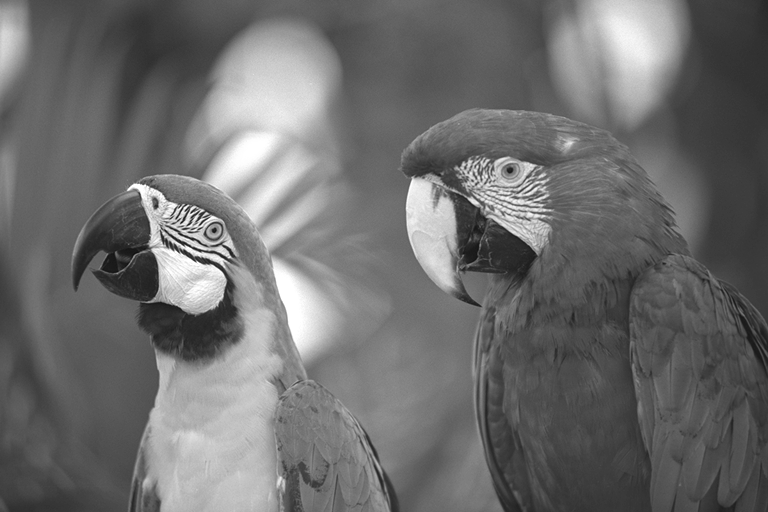

Animal Classification Results:
parrot: 99.83%
rabbit: 0.06%
dog: 0.05%
cat: 0.04%
horse: 0.02%


In [ ]:
# CAPSTONE 51 - Step 5: Test animal image classification

from PIL import Image
from IPython.display import display
import requests
from io import BytesIO

# Download a sample parrot image
image_url = "https://huggingface.co/datasets/Narsil/image_dummy/raw/main/parrots.png"

response = requests.get(image_url, timeout=30)
response.raise_for_status()

image = Image.open(BytesIO(response.content)).convert("RGB")

# Display the image
display(image)

# Possible animal categories
candidate_labels = ["cat", "dog", "parrot", "horse", "rabbit"]

# Predict the animal
results = classifier(image, candidate_labels=candidate_labels)

print("Animal Classification Results:")
for result in results:
    print(f"{result['label']}: {result['score']:.2%}")

In [ ]:
# CAPSTONE 51 - Step 6: Prepare the evaluation table

import pandas as pd

results_table = pd.DataFrame(columns=[
    "Image Number",
    "Actual Animal",
    "Predicted Animal",
    "Model Score (%)",
    "Correct?",
    "Failure Notes"
])

display(results_table)

,Image Number,Actual Animal,Predicted Animal,Model Score (%),Correct?,Failure Notes


In [10]:
# CAPSTONE 51 - Step 8: Predict the animal using CLIP

import torch

# Possible labels for the image
labels = [
    "a photo of a parrot",
    "a photo of a rabbit",
    "a photo of a dog",
    "a photo of a cat",
    "a photo of a horse"
]

# Prepare the image and text together
inputs = processor(
    text=labels,
    images=my_image,
    return_tensors="pt",
    padding=True
)

# Get predictions
with torch.no_grad():
    outputs = model(**inputs)

# Convert scores into probabilities
probs = outputs.logits_per_image.softmax(dim=1)[0]

best_index = probs.argmax().item()
predicted_label = labels[best_index]
confidence = probs[best_index].item() * 100

print("Actual animal: Parrot")
print("Model prediction:", predicted_label)
print(f"CLIP score among these labels: {confidence:.2f}%")

Actual animal: Parrot
Model prediction: a photo of a parrot
CLIP score among these labels: 99.88%


In [11]:
# CAPSTONE 51 - Step 8: Predict the animal using CLIP

import torch

# Possible labels for the image
labels = [
    "a photo of a parrot",
    "a photo of a rabbit",
    "a photo of a dog",
    "a photo of a cat",
    "a photo of a horse"
]

# Prepare the image and text together
inputs = processor(
    text=labels,
    images=my_image,
    return_tensors="pt",
    padding=True
)

# Get predictions
with torch.no_grad():
    outputs = model(**inputs)

# Convert scores into probabilities
probs = outputs.logits_per_image.softmax(dim=1)[0]

best_index = probs.argmax().item()
predicted_label = labels[best_index]
confidence = probs[best_index].item() * 100

print("Actual animal: Parrot")
print("Model prediction:", predicted_label)
print(f"CLIP score among these labels: {confidence:.2f}%")

Actual animal: Parrot
Model prediction: a photo of a parrot
CLIP score among these labels: 99.88%


Sample animal image downloaded successfully!


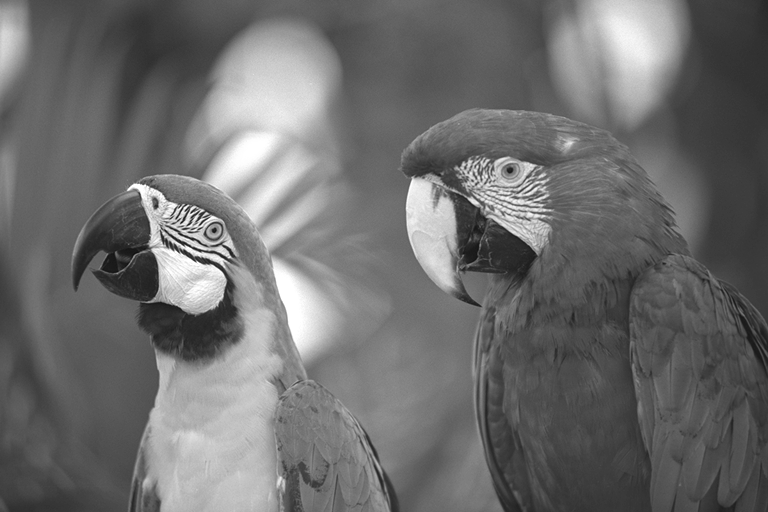

In [1]:
# CAPSTONE 51 - Step 7: Download sample animal images

import requests
from PIL import Image
from IPython.display import display
from io import BytesIO

image_url = "https://huggingface.co/datasets/Narsil/image_dummy/raw/main/parrots.png"

response = requests.get(image_url, timeout=30)
response.raise_for_status()

my_image = Image.open(BytesIO(response.content)).convert("RGB")

print("Sample animal image downloaded successfully!")
display(my_image)

In [6]:
# CAPSTONE 51 - Step 8A: Load the model

from transformers import CLIPModel

model = CLIPModel.from_pretrained(
    "openai/clip-vit-base-patch32"
)

print("Model loaded successfully!")


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Model loaded successfully!


In [4]:
from transformers import CLIPProcessor

processor = CLIPProcessor.from_pretrained(
    "openai/clip-vit-base-patch32"
)

print("Image processor loaded successfully!")


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Image processor loaded successfully!


In [12]:
# CAPSTONE 51 - Step 9.1
# Load the Oxford-IIIT Pet Dataset

!pip install -q torchvision

from torchvision.datasets import OxfordIIITPet

dataset = OxfordIIITPet(
    root="/content/oxford_pets",
    split="test",
    target_types="category",
    download=True
)

print("Dataset loaded successfully!")
print("Number of test images:", len(dataset))
print("First image size:", dataset[0][0].size)
print("First image label:", dataset[0][1])

100%|██████████| 792M/792M [01:08<00:00, 11.5MB/s]
100%|██████████| 19.2M/19.2M [00:02<00:00, 6.55MB/s]


Dataset loaded successfully!
Number of test images: 3669
First image size: (300, 225)
First image label: 0


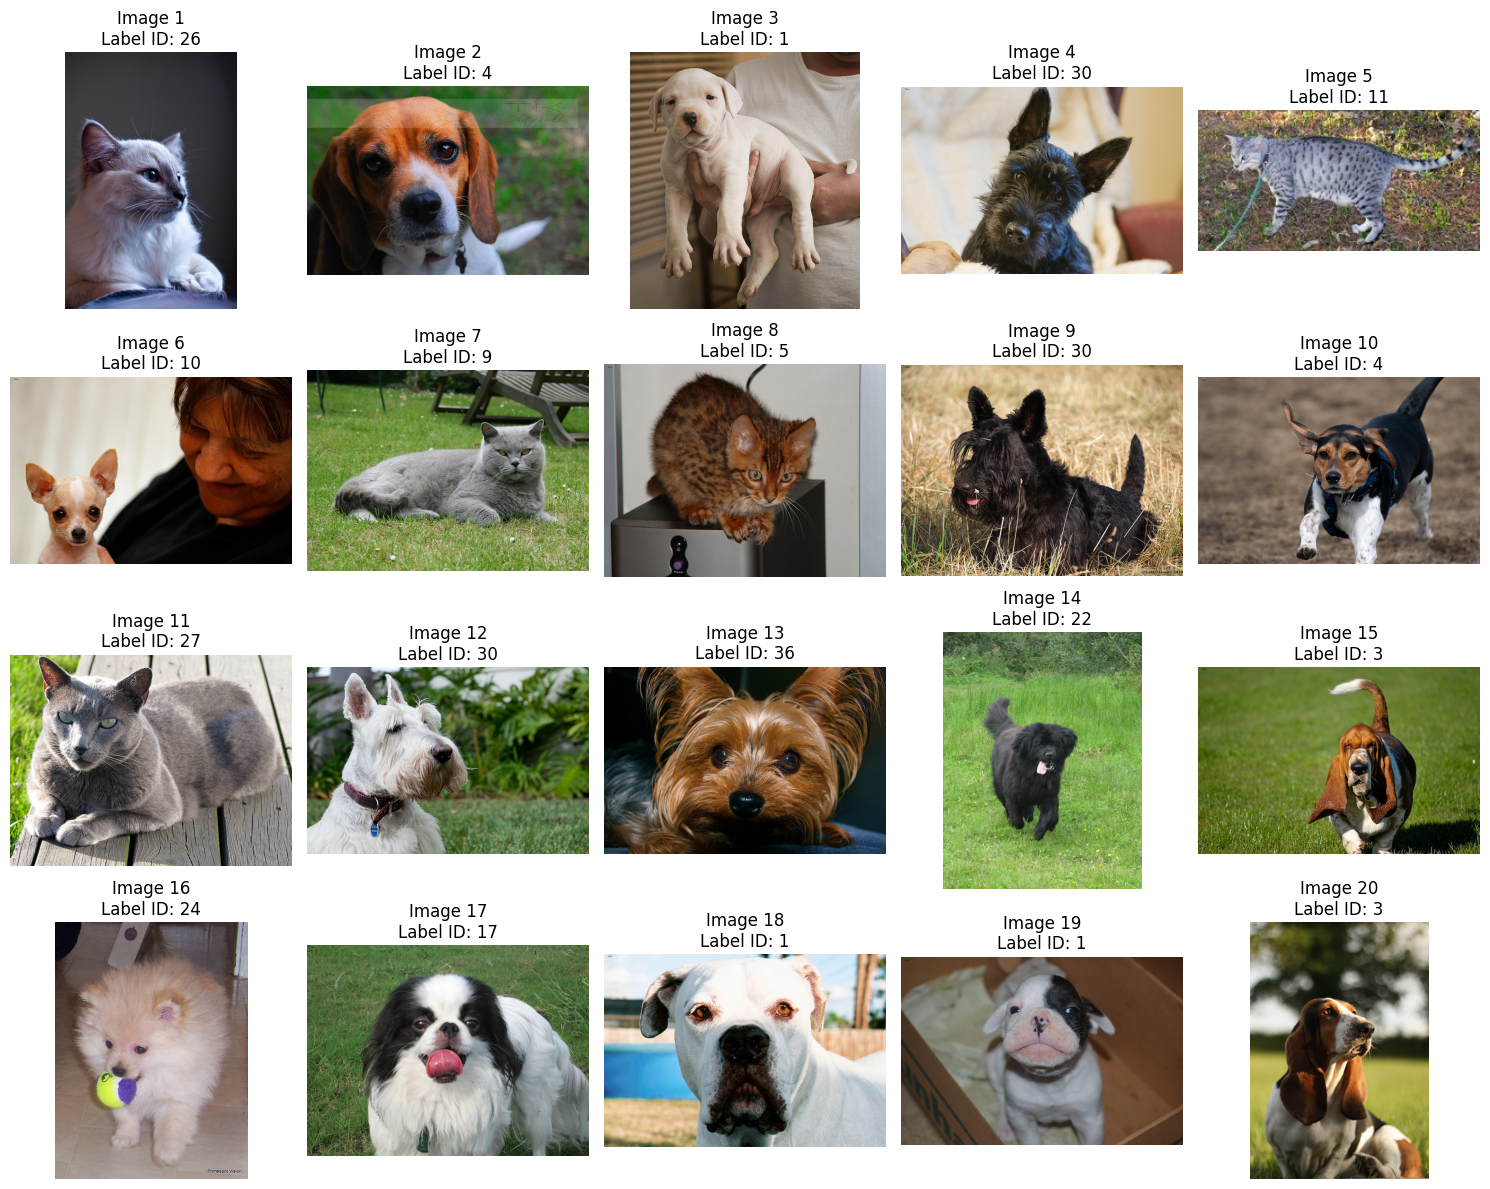

Selected 20 images successfully!


In [13]:
# CAPSTONE 51 - Step 9.2
# Select 20 test images

import random
import matplotlib.pyplot as plt

random.seed(42)

sample_indices = random.sample(range(len(dataset)), 20)

plt.figure(figsize=(15, 12))

for i, idx in enumerate(sample_indices):
    image, label = dataset[idx]

    plt.subplot(4, 5, i + 1)
    plt.imshow(image)
    plt.title(f"Image {i + 1}\nLabel ID: {label}")
    plt.axis("off")

plt.tight_layout()
plt.show()

print("Selected 20 images successfully!")

In [15]:
# CAPSTONE 51 - Step 9.3
# Predict breeds for 20 test images

import torch
import pandas as pd
from tqdm.auto import tqdm
from pathlib import Path

# Get breed names from image filenames
breed_names = sorted({
    Path(str(dataset._images[i])).stem.rsplit("_", 1)[0]
    for i in range(len(dataset))
})

labels = [
    f"a photo of a {breed.replace('_', ' ')} pet"
    for breed in breed_names
]

results = []
model.eval()

for idx in tqdm(sample_indices, desc="Testing images"):
    image, actual_label_id = dataset[idx]

    # Get the actual breed from the image filename
    actual_breed = Path(str(dataset._images[idx])).stem
    actual_breed = actual_breed.rsplit("_", 1)[0]

    inputs = processor(
        text=labels,
        images=image,
        return_tensors="pt",
        padding=True
    )

    with torch.no_grad():
        outputs = model(**inputs)

    scores = outputs.logits_per_image.softmax(dim=1)[0]
    predicted_index = scores.argmax().item()
    predicted_breed = breed_names[predicted_index]

    results.append({
        "Image Index": idx,
        "Actual Breed": actual_breed.replace("_", " "),
        "Predicted Breed": predicted_breed.replace("_", " "),
        "Score (%)": round(scores[predicted_index].item() * 100, 2),
        "Correct": actual_breed.lower() == predicted_breed.lower()
    })

results_df = pd.DataFrame(results)

display(results_df)

correct_count = int(results_df["Correct"].sum())
accuracy = correct_count / len(results_df) * 100

print(f"Correct predictions: {correct_count} out of {len(results_df)}")
print(f"Accuracy on this 20-image sample: {accuracy:.2f}%")

Testing images:   0%|          | 0/20 [00:00<?, ?it/s]

,Image Index,Actual Breed,Predicted Breed,Score (%),Correct
0,2619,Ragdoll,Ragdoll,64.59,True
1,456,beagle,beagle,93.02,True
2,102,american bulldog,american bulldog,79.86,True
3,3037,scottish terrier,scottish terrier,99.98,True
4,1126,Egyptian Mau,Egyptian Mau,99.32,True
5,1003,chihuahua,chihuahua,56.94,True
6,914,British Shorthair,British Shorthair,98.50,True
7,571,Bengal,Bengal,38.72,True
8,3016,scottish terrier,scottish terrier,99.99,True
9,419,beagle,basset hound,52.34,False


Correct predictions: 19 out of 20
Accuracy on this 20-image sample: 95.00%


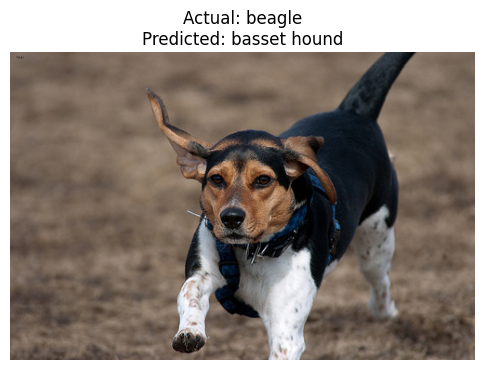

Image index: 419
Actual breed: beagle
Predicted breed: basset hound


In [16]:
# CAPSTONE 51 - Step 9.4
# Inspect the incorrectly classified image

wrong_rows = results_df[results_df["Correct"] == False]

for _, row in wrong_rows.iterrows():
    idx = int(row["Image Index"])
    image, actual_label = dataset[idx]

    plt.figure(figsize=(6, 5))
    plt.imshow(image)
    plt.title(
        f"Actual: {row['Actual Breed']}\n"
        f"Predicted: {row['Predicted Breed']}"
    )
    plt.axis("off")
    plt.show()

    print("Image index:", idx)
    print("Actual breed:", row["Actual Breed"])
    print("Predicted breed:", row["Predicted Breed"])

In [17]:
# CAPSTONE 51 - Step 9.5
# Compare an alternative text prompt

improved_labels = [
    f"a clear photograph of a {breed.replace('_', ' ')}, showing its distinctive breed features"
    for breed in breed_names
]

improved_results = []

for idx in tqdm(sample_indices, desc="Testing improved prompts"):
    image, actual_label_id = dataset[idx]

    actual_breed = str(dataset._images[idx])
    actual_breed = Path(actual_breed).stem.rsplit("_", 1)[0]

    inputs = processor(
        text=improved_labels,
        images=image,
        return_tensors="pt",
        padding=True
    )

    with torch.no_grad():
        outputs = model(**inputs)

    scores = outputs.logits_per_image.softmax(dim=1)[0]
    predicted_index = scores.argmax().item()
    predicted_breed = breed_names[predicted_index]

    improved_results.append({
        "Image Index": idx,
        "Actual Breed": actual_breed.replace("_", " "),
        "Predicted Breed": predicted_breed.replace("_", " "),
        "Score (%)": round(scores[predicted_index].item() * 100, 2),
        "Correct": actual_breed.lower() == predicted_breed.lower()
    })

improved_df = pd.DataFrame(improved_results)

display(improved_df)

before_accuracy = results_df["Correct"].mean() * 100
after_accuracy = improved_df["Correct"].mean() * 100

print(f"Before prompt change: {before_accuracy:.2f}%")
print(f"After prompt change:  {after_accuracy:.2f}%")
print(f"Change: {after_accuracy - before_accuracy:+.2f} percentage points")

Testing improved prompts:   0%|          | 0/20 [00:00<?, ?it/s]

,Image Index,Actual Breed,Predicted Breed,Score (%),Correct
0,2619,Ragdoll,Ragdoll,56.15,True
1,456,beagle,beagle,93.88,True
2,102,american bulldog,american bulldog,81.35,True
3,3037,scottish terrier,scottish terrier,99.98,True
4,1126,Egyptian Mau,Egyptian Mau,98.52,True
5,1003,chihuahua,chihuahua,78.76,True
6,914,British Shorthair,British Shorthair,92.23,True
7,571,Bengal,Abyssinian,35.39,False
8,3016,scottish terrier,scottish terrier,100.00,True
9,419,beagle,beagle,67.01,True


Before prompt change: 95.00%
After prompt change:  95.00%
Change: +0.00 percentage points


In [18]:
# CAPSTONE 51 - Step 9.6
# Save experimental results

results_df.to_csv(
    "/content/before_prompt_results.csv",
    index=False
)

improved_df.to_csv(
    "/content/after_prompt_results.csv",
    index=False
)

print("Results saved successfully!")
print("1. before_prompt_results.csv")
print("2. after_prompt_results.csv")

Results saved successfully!
1. before_prompt_results.csv
2. after_prompt_results.csv


In [19]:
from google.colab import files

files.download("/content/before_prompt_results.csv")
files.download("/content/after_prompt_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
# CAPSTONE 51 - Step 10
# Create the failure analysis report

report = """
# Failure Analysis Report

## Project
Image Classification Mini-Project with Hugging Face

## Model
CLIP: openai/clip-vit-base-patch32

## Dataset
Oxford-IIIT Pet Dataset

## Test Results
- Images tested: 20
- Correct predictions: 19
- Incorrect predictions: 1
- Sample accuracy: 95%

## Incorrect Prediction

- Image index: 419
- Actual breed: Beagle
- Predicted breed: Basset Hound
- Prediction score: 52.34%

## Possible Explanation
The model may have confused the Beagle with the Basset Hound
because of visual similarities. This is a hypothesis and requires
further image inspection to confirm.

## Prompt Improvement Experiment

- Original prompt accuracy: 95%
- Alternative prompt accuracy: 95%
- Accuracy change: 0 percentage points

The alternative prompt did not improve accuracy on this
20-image sample.

## Limitations
- Only 20 test images were evaluated.
- Results may vary on a larger or different sample.
- Prediction scores are relative to the candidate breed labels;
  they are not guaranteed to represent calibrated confidence.
- The experiment does not establish overall dataset accuracy.

## Conclusion
The model correctly classified 19 of the 20 selected images.
Changing the prompt wording did not improve the measured accuracy.
Further testing is needed to evaluate other improvement methods.
"""

with open("/content/failure_analysis.md", "w") as f:
    f.write(report)

print("Failure analysis report created successfully!")

Failure analysis report created successfully!


In [21]:
from google.colab import files

files.download("/content/failure_analysis.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>